In [1]:
from google.cloud import bigquery
import pandas as pd

PROJECT_ID = "sincere-quasar-511010-v3"

client = bigquery.Client(project=PROJECT_ID)

query = """
SELECT
    DATE(c.date) AS ds,
    SUM(s.total_units_sold) AS y
FROM `sincere-quasar-511010-v3.retail_demand_dbt.fct_weekly_sales` AS s
JOIN `sincere-quasar-511010-v3.retail_demand_raw.calendar` AS c
    ON CAST(s.week_id AS STRING) = CAST(c.wm_yr_wk AS STRING)
GROUP BY ds
ORDER BY ds
"""

forecast_df = client.query(query).to_dataframe()

forecast_df.head()

c:\Users\babyp\Project-3-Retail-Demand-Forecasting-Inventory-Optimization\venv\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,ds,y
0,2011-01-29,189942
1,2011-01-30,189942
2,2011-01-31,189942
3,2011-02-01,189942
4,2011-02-02,189942


Importing plotly failed. Interactive plots will not work.
11:08:37 - cmdstanpy - INFO - Chain [1] start processing
11:08:38 - cmdstanpy - INFO - Chain [1] done processing


MAE: 188997.61
RMSE: 188997.61


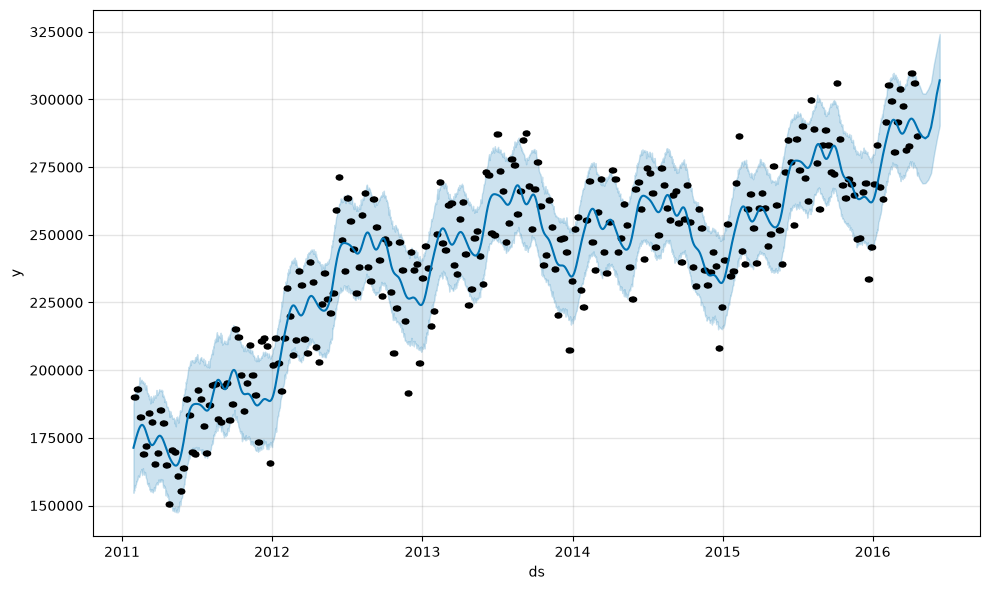

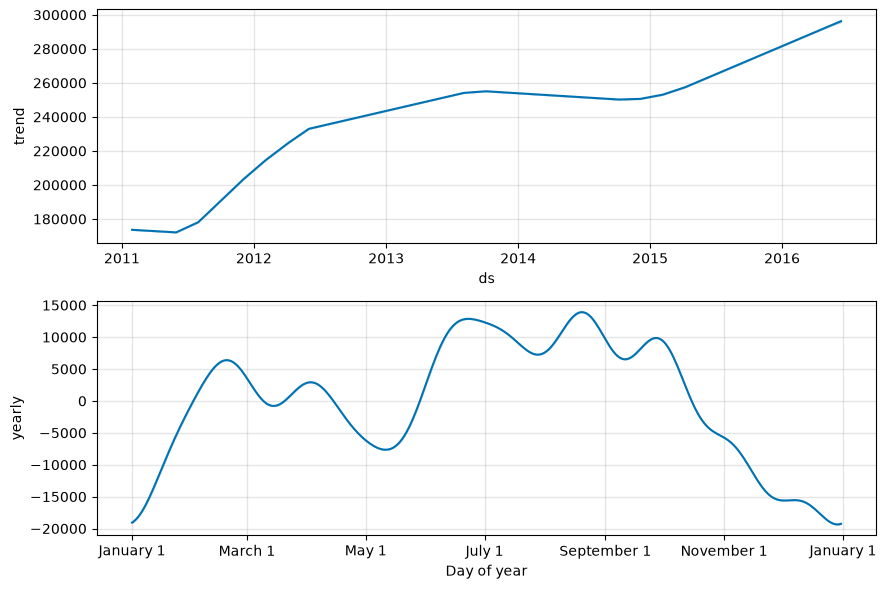

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

forecast_df = forecast_df[["ds", "y"]].copy()
forecast_df["ds"] = pd.to_datetime(forecast_df["ds"])
forecast_df["y"] = pd.to_numeric(forecast_df["y"], errors="coerce")
forecast_df = forecast_df.dropna().sort_values("ds")

# Hold out the latest 8 weeks for evaluation
train = forecast_df.iloc[:-8].copy()
test = forecast_df.iloc[-8:].copy()

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)
model.fit(train)

future = model.make_future_dataframe(periods=8, freq="W")
forecast = model.predict(future)

predictions = forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(8)
evaluation = test.merge(predictions, on="ds")

mae = mean_absolute_error(evaluation["y"], evaluation["yhat"])
rmse = np.sqrt(mean_squared_error(evaluation["y"], evaluation["yhat"]))

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

model.plot(forecast)
plt.show()

model.plot_components(forecast)
plt.show()

In [3]:
# Show variables that may contain the Prophet forecast
print([name for name in globals()
       if any(word in name.lower()
              for word in ["forecast", "prophet", "actual", "test"])])

['forecast_df', 'Prophet', 'test', 'forecast']


In [4]:
print("Forecast DataFrame columns:")
print(forecast_df.columns.tolist())

print("\nForecast DataFrame shape:")
print(forecast_df.shape)

print("\nFirst 5 forecast rows:")
display(forecast_df.head())

Forecast DataFrame columns:
['ds', 'y']

Forecast DataFrame shape:
(1918, 2)

First 5 forecast rows:


,ds,y
0,2011-01-29,189942
1,2011-01-30,189942
2,2011-01-31,189942
3,2011-02-01,189942
4,2011-02-02,189942


In [5]:
print("Forecast type:", type(forecast))

if hasattr(forecast, "columns"):
    print("Forecast columns:", forecast.columns.tolist())
    display(forecast.head())
else:
    print(forecast)

Forecast type: <class 'pandas.DataFrame'>
Forecast columns: ['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper', 'additive_terms', 'additive_terms_lower', 'additive_terms_upper', 'yearly', 'yearly_lower', 'yearly_upper', 'multiplicative_terms', 'multiplicative_terms_lower', 'multiplicative_terms_upper', 'yhat']


,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2011-01-29,173653.038409,154692.261966,187352.604066,173653.038409,173653.038409,-2322.323310,-2322.323310,-2322.323310,-2322.323310,-2322.323310,-2322.323310,0.0,0.0,0.0,171330.715099
1,2011-01-30,173640.567273,155817.260396,189673.458495,173640.567273,173640.567273,-1723.687769,-1723.687769,-1723.687769,-1723.687769,-1723.687769,-1723.687769,0.0,0.0,0.0,171916.879504
2,2011-01-31,173628.096137,155473.587257,189659.030271,173628.096137,173628.096137,-1133.502318,-1133.502318,-1133.502318,-1133.502318,-1133.502318,-1133.502318,0.0,0.0,0.0,172494.593819
3,2011-02-01,173615.625001,157533.616940,189169.478454,173615.625001,173615.625001,-551.298771,-551.298771,-551.298771,-551.298771,-551.298771,-551.298771,0.0,0.0,0.0,173064.326230
4,2011-02-02,173603.153865,156617.553583,190045.420200,173603.153865,173603.153865,23.006464,23.006464,23.006464,23.006464,23.006464,23.006464,0.0,0.0,0.0,173626.160328


In [6]:
print("Has predicted demand (yhat):", "yhat" in forecast.columns)

display(
    forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].head()
)

Has predicted demand (yhat): True


,ds,yhat,yhat_lower,yhat_upper
0,2011-01-29,171330.715099,154692.261966,187352.604066
1,2011-01-30,171916.879504,155817.260396,189673.458495
2,2011-01-31,172494.593819,155473.587257,189659.030271
3,2011-02-01,173064.326230,157533.616940,189169.478454
4,2011-02-02,173626.160328,156617.553583,190045.420200


In [7]:
print("Training data columns:")
print(train.columns.tolist())

print("\nTraining data shape:")
print(train.shape)

print("\nTraining data sample:")
display(train.head())

print("\nTest data columns:")
print(test.columns.tolist())

Training data columns:
['ds', 'y']

Training data shape:
(1910, 2)

Training data sample:


,ds,y
0,2011-01-29,189942
1,2011-01-30,189942
2,2011-01-31,189942
3,2011-02-01,189942
4,2011-02-02,189942



Test data columns:
['ds', 'y']


In [8]:
print("Variables related to sales or aggregation:")
print([
    name for name in globals()
    if any(word in name.lower()
           for word in ["sales", "daily", "total", "group", "actual"])
])

print("\nActual values summary:")
print(train["y"].describe())

Variables related to sales or aggregation:
[]

Actual values summary:
count           1910.0
mean     240256.565445
std       34265.981064
min           150519.0
25%           221133.0
50%           245683.0
75%           265580.0
max           309668.0
Name: y, dtype: Float64


In [9]:
forecast.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2011-01-29,173653.038409,154692.261966,187352.604066,173653.038409,173653.038409,-2322.323310,-2322.323310,-2322.323310,-2322.323310,-2322.323310,-2322.323310,0.0,0.0,0.0,171330.715099
1,2011-01-30,173640.567273,155817.260396,189673.458495,173640.567273,173640.567273,-1723.687769,-1723.687769,-1723.687769,-1723.687769,-1723.687769,-1723.687769,0.0,0.0,0.0,171916.879504
2,2011-01-31,173628.096137,155473.587257,189659.030271,173628.096137,173628.096137,-1133.502318,-1133.502318,-1133.502318,-1133.502318,-1133.502318,-1133.502318,0.0,0.0,0.0,172494.593819
3,2011-02-01,173615.625001,157533.616940,189169.478454,173615.625001,173615.625001,-551.298771,-551.298771,-551.298771,-551.298771,-551.298771,-551.298771,0.0,0.0,0.0,173064.326230
4,2011-02-02,173603.153865,156617.553583,190045.420200,173603.153865,173603.153865,23.006464,23.006464,23.006464,23.006464,23.006464,23.006464,0.0,0.0,0.0,173626.160328


In [10]:
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].head()

,ds,yhat,yhat_lower,yhat_upper
0,2011-01-29,171330.715099,154692.261966,187352.604066
1,2011-01-30,171916.879504,155817.260396,189673.458495
2,2011-01-31,172494.593819,155473.587257,189659.030271
3,2011-02-01,173064.326230,157533.616940,189169.478454
4,2011-02-02,173626.160328,156617.553583,190045.420200


In [11]:
prophet_upload = forecast[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].copy()

prophet_upload = prophet_upload.rename(columns={
    "ds": "forecast_date",
    "yhat": "predicted_units",
    "yhat_lower": "lower_bound",
    "yhat_upper": "upper_bound"
})

prophet_upload["forecast_date"] = pd.to_datetime(
    prophet_upload["forecast_date"]
).dt.date

prophet_upload.head()

,forecast_date,predicted_units,lower_bound,upper_bound
0,2011-01-29,171330.715099,154692.261966,187352.604066
1,2011-01-30,171916.879504,155817.260396,189673.458495
2,2011-01-31,172494.593819,155473.587257,189659.030271
3,2011-02-01,173064.326230,157533.616940,189169.478454
4,2011-02-02,173626.160328,156617.553583,190045.420200


In [12]:
from google.cloud import bigquery

PROJECT_ID = "sincere-quasar-511010-v3"
TABLE_ID = f"{PROJECT_ID}.retail_demand_raw.prophet_forecast_results"

client = bigquery.Client(project=PROJECT_ID)

job_config = bigquery.LoadJobConfig(
    write_disposition=bigquery.WriteDisposition.WRITE_APPEND,
    schema=[
        bigquery.SchemaField("forecast_date", "DATE"),
        bigquery.SchemaField("predicted_units", "FLOAT64"),
        bigquery.SchemaField("lower_bound", "FLOAT64"),
        bigquery.SchemaField("upper_bound", "FLOAT64"),
    ],
)

job = client.load_table_from_dataframe(
    prophet_upload,
    TABLE_ID,
    job_config=job_config,
)

job.result()

print("Prophet forecast uploaded successfully!")
print("Rows uploaded:", job.output_rows)
print("Destination:", TABLE_ID)

Prophet forecast uploaded successfully!
Rows uploaded: 1918
Destination: sincere-quasar-511010-v3.retail_demand_raw.prophet_forecast_results
